# Praktikum Kecerdasan Buatan

## Text Clustering for Movies

Topik : Text Clustering (K-Means)

Nama : Tika Altiora Sitanggang

NIM : 42324025

Program Studi : D3TI

## 1. Tujuan dan Gambaran Singkat

Tujuan praktikum ini adalah melakukan semua tahap klasterisasi teks, mulai dari membaca data sampai membaca hasil klasternya.

Data yang dipakai adalah `Text.csv`, yaitu kumpulan sekitar 5.500 pesan teks singkat (SMS). Teks yang dikelompokkan ada di kolom `Message`. Idenya, pesan yang memakai kata-kata mirip akan masuk ke klaster yang sama, tanpa kita memberi label apa pun di awal. Karena itu ini termasuk *unsupervised learning*.

Kolom `Category` (ham/spam) memang ada di file, tetapi **tidak dipakai** untuk proses klasterisasi. Kolom itu hanya dipakai di akhir sebagai bahan perbandingan.

Tahapan yang dikerjakan di notebook ini:

1. Import library
2. Membaca dataset
3. Membersihkan data (cek nilai kosong)
4. Preprocessing teks (lowercase, hapus angka dan tanda baca, tokenisasi, lemmatization)
5. Mengubah teks menjadi angka dengan TF-IDF
6. Clustering dengan K-Means (jumlah klaster 2, sesuai modul)
7. Visualisasi dengan PCA
8. Membaca isi tiap klaster (kata penciri dan contoh pesan)
9. Mencoba jumlah klaster lain dan membandingkannya
10. Kesimpulan

> Catatan: file `Text.csv` harus berada satu folder dengan notebook ini supaya bisa terbaca.

## Tahap 1. Import Library

Sebelum mulai, semua library yang dibutuhkan dipanggil dulu. Fungsi tiap library:

| Library | Fungsinya di notebook ini |
|---|---|
| `pandas` | membaca file CSV dan mengolah data dalam bentuk tabel (DataFrame) |
| `numpy` | membantu perhitungan angka dan array |
| `re` | *regular expression*, dipakai untuk menghapus angka dari teks |
| `string` | menyediakan daftar tanda baca yang akan dihapus |
| `nltk` (`word_tokenize`, `WordNetLemmatizer`) | memecah kalimat menjadi kata dan mengubah kata ke bentuk dasarnya |
| `TfidfVectorizer` | mengubah teks menjadi angka dengan metode TF-IDF |
| `KMeans` | algoritma clustering |
| `PCA` | memperkecil dimensi data supaya bisa digambar dalam 2 dimensi |
| `silhouette_score` | mengukur seberapa bagus hasil klaster (dipakai di tahap 9) |
| `matplotlib` | membuat grafik |

NLTK membutuhkan beberapa data tambahan (`punkt` untuk tokenisasi dan `wordnet` untuk lemmatization), jadi di sel ini juga ada perintah `nltk.download`. Kalau sudah pernah terunduh, perintah ini tidak mengunduh ulang.

In [1]:
# Import library
import os
import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Unduh data pendukung NLTK (hanya perlu sekali)
for paket in ['punkt', 'punkt_tab', 'wordnet', 'omw-1.4']:
    nltk.download(paket, quiet=True)

print("Semua library berhasil di-import")

Semua library berhasil di-import


## Tahap 2. Membaca Dataset

Data dibaca dengan `pd.read_csv()`. Setelah itu kolom `Message` diganti namanya menjadi `text` dengan `rename()`, supaya nama kolomnya lebih singkat dan gampang dipanggil di langkah berikutnya.

Setelah dibaca, kita lihat dulu 5 baris pertama, ukuran data (jumlah baris dan kolom), dan jumlah pesan untuk tiap `Category`. Tujuannya untuk memastikan data terbaca dengan benar.

In [2]:
# Load dataset
file_path = "Text.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError("File Text.csv tidak ditemukan. Pastikan satu folder dengan notebook ini.")

df = pd.read_csv(file_path)

# Kolom Message diganti namanya menjadi text, kolom inilah yang akan diklasterisasi
df = df.rename(columns={'Message': 'text'})

print("Ukuran data (baris, kolom):", df.shape)
print()
print(df['Category'].value_counts())
df.head()

Ukuran data (baris, kolom): (5572, 2)

Category
ham     4825
spam     747
Name: count, dtype: int64


,Category,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Tahap 3. Membersihkan Data (Cek Nilai Kosong)

Sebelum teks diolah, perlu dicek apakah ada baris yang kosong. Teks yang kosong bisa membuat fungsi preprocessing error, jadi baris seperti itu dibuang dulu dengan `dropna()`.

Di sini juga dicek jumlah pesan yang isinya sama persis (duplikat). Pesan duplikat **tidak dihapus**, supaya data yang dipakai tetap sama dengan yang ada di modul. Pengecekan ini hanya untuk informasi.

In [3]:
# Cek nilai kosong
print("Jumlah nilai kosong per kolom:")
print(df.isnull().sum())

# Buang baris yang teksnya kosong (kalau ada)
sebelum = len(df)
df = df.dropna(subset=['text']).reset_index(drop=True)
print()
print("Baris sebelum dibersihkan :", sebelum)
print("Baris sesudah dibersihkan :", len(df))

# Hanya informasi: jumlah pesan yang sama persis
print("Jumlah pesan duplikat      :", df['text'].duplicated().sum())

Jumlah nilai kosong per kolom:
Category    0
text        0
dtype: int64

Baris sebelum dibersihkan : 5572
Baris sesudah dibersihkan : 5572
Jumlah pesan duplikat      : 415


## Tahap 4. Preprocessing Teks

Komputer tidak bisa langsung memahami teks mentah, dan teks SMS biasanya berantakan (huruf besar kecil campur, banyak angka, banyak tanda baca). Karena itu teks dibersihkan dulu lewat fungsi `clean_text()` dengan 5 langkah:

1. **Lowercasing**: semua huruf diubah ke huruf kecil, supaya kata `Free` dan `free` dianggap sama.
2. **Hapus angka**: angka dibuang dengan `re.sub(r'\d+', '', text)`.
3. **Hapus tanda baca**: tanda baca dibuang memakai `str.maketrans` dan `string.punctuation`.
4. **Tokenisasi**: kalimat dipecah menjadi daftar kata dengan `word_tokenize()`.
5. **Lemmatization**: tiap kata diubah ke bentuk dasarnya dengan `WordNetLemmatizer`. Contohnya `messages` menjadi `message`.

Terakhir kata-kata digabung lagi menjadi satu kalimat dengan `' '.join(words)`, lalu fungsi ini diterapkan ke semua baris dengan `apply()` dan hasilnya disimpan di kolom baru `clean_text`.

Untuk membuktikan fungsinya bekerja, ditampilkan perbandingan teks asli dan teks setelah dibersihkan.

In [4]:
# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()

# Fungsi preprocessing teks
def clean_text(text):
    text = text.lower()                                                   # Lowercasing
    text = re.sub(r'\d+', '', text)                                       # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation))      # Hapus tanda baca
    words = word_tokenize(text)                                           # Tokenisasi
    words = [lemmatizer.lemmatize(word) for word in words]                # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text'] = df['text'].apply(clean_text)

# Bandingkan teks asli dengan hasil pembersihan
pd.set_option('display.max_colwidth', 120)
df[['text', 'clean_text']].head(5)

,text,clean_text
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,free entry in a wkly comp to win fa cup final tkts st may text fa to to receive entry questionstd txt ratetcs apply ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives around here though",nah i dont think he go to usf he life around here though


## Tahap 5. Mengubah Teks Menjadi Angka dengan TF-IDF

K-Means bekerja dengan angka, jadi teks yang sudah bersih harus diubah menjadi vektor angka. Metode yang dipakai adalah **TF-IDF** (*Term Frequency - Inverse Document Frequency*). Cara kerjanya secara singkat:

- **TF**: seberapa sering sebuah kata muncul dalam satu pesan.
- **IDF**: kata yang muncul di hampir semua pesan dianggap kurang penting, sedangkan kata yang jarang muncul tapi khas dianggap lebih penting.

Nilai TF dan IDF dikalikan, sehingga kata yang khas untuk suatu pesan mendapat nilai tinggi.

Pada `TfidfVectorizer(stop_words='english')`, parameter `stop_words='english'` membuang kata-kata umum bahasa Inggris seperti *the*, *is*, *and*, karena kata seperti itu tidak membantu membedakan pesan.

Hasilnya berupa matriks `X`: tiap baris mewakili satu pesan dan tiap kolom mewakili satu kata unik. Sebagian besar isinya 0, karena satu pesan hanya memuat sedikit kata dari seluruh kosakata.

In [5]:
# Konversi teks ke vektor TF-IDF
vectorizer = TfidfVectorizer(stop_words='english')  # Menggunakan stopwords dari sklearn
X = vectorizer.fit_transform(df['clean_text'])

print("Ukuran matriks TF-IDF (jumlah pesan, jumlah kata unik):", X.shape)

# Persentase isi matriks yang bernilai 0
persen_nol = (1 - X.nnz / (X.shape[0] * X.shape[1])) * 100
print(f"Persentase nilai 0 dalam matriks: {persen_nol:.2f}%")

Ukuran matriks TF-IDF (jumlah pesan, jumlah kata unik): (5572, 7797)
Persentase nilai 0 dalam matriks: 99.91%


## Tahap 6. Clustering dengan K-Means

K-Means mengelompokkan data ke dalam sejumlah klaster yang kita tentukan di awal. Prosesnya:

1. Pilih titik pusat (*centroid*) sebanyak jumlah klaster.
2. Tiap pesan dimasukkan ke klaster dengan centroid terdekat.
3. Centroid dihitung ulang dari rata-rata anggota klasternya.
4. Langkah 2 dan 3 diulang sampai posisi centroid tidak banyak berubah.

Sesuai modul, jumlah klaster yang dipakai adalah **2** (`num_clusters = 2`). Penjelasan parameter lainnya:

- `random_state=42` supaya hasilnya sama setiap kali notebook dijalankan.
- `n_init=10` artinya K-Means dijalankan 10 kali dengan titik awal berbeda, lalu diambil hasil yang terbaik.

`fit_predict(X)` melatih model sekaligus memberi nomor klaster (0 atau 1) untuk tiap pesan, dan nomornya disimpan di kolom `cluster`.

In [6]:
# Tentukan jumlah klaster
num_clusters = 2
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

# Jumlah pesan di tiap klaster
print("Jumlah pesan per klaster:")
print(df['cluster'].value_counts().sort_index())

Jumlah pesan per klaster:
cluster
0    5371
1     201
Name: count, dtype: int64


## Tahap 7. Visualisasi dengan PCA

Matriks TF-IDF punya ribuan kolom, sehingga tidak mungkin digambar langsung. **PCA** (*Principal Component Analysis*) dipakai untuk memperkecil dimensi data menjadi 2 komponen saja, dengan tetap menyimpan informasi sebanyak mungkin. Setelah itu tiap pesan bisa digambar sebagai satu titik, dan warnanya menunjukkan klasternya.

`X.toarray()` dipakai karena PCA butuh matriks biasa, bukan matriks sparse. Nilai `explained_variance_ratio_` menunjukkan berapa persen informasi data yang masih terwakili oleh tiap komponen.

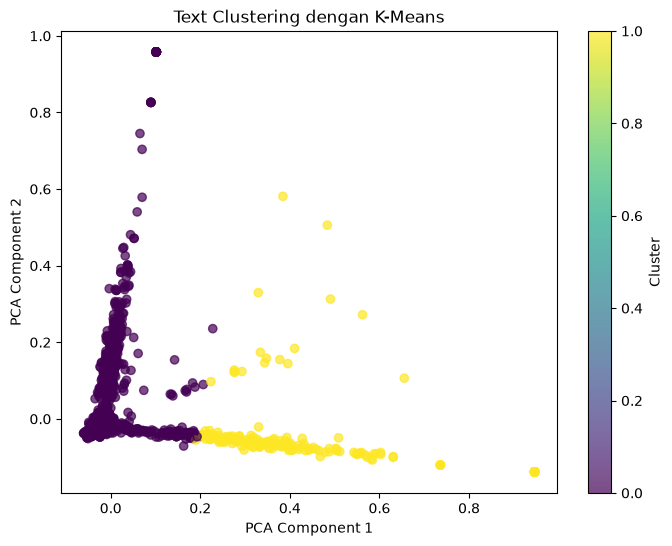

Informasi yang terwakili PCA 1 : 0.95 %
Informasi yang terwakili PCA 2 : 0.91 %
Total kedua komponen           : 1.86 %


In [7]:
# Visualisasi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', alpha=0.7)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Text Clustering dengan K-Means")
plt.colorbar(label='Cluster')
plt.show()

print("Informasi yang terwakili PCA 1 :", round(pca.explained_variance_ratio_[0] * 100, 2), "%")
print("Informasi yang terwakili PCA 2 :", round(pca.explained_variance_ratio_[1] * 100, 2), "%")
print("Total kedua komponen           :", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

**Cara membaca grafik di atas:**

- Setiap titik adalah satu pesan, dan warna titik menunjukkan klasternya (0 atau 1).
- Titik yang berdekatan berarti pesan-pesan itu punya kata-kata yang mirip.
- Karena PCA hanya menyimpan sebagian kecil informasi data (lihat persentase di bawah grafik), pemisahan klaster di gambar tidak akan terlihat sempurna. Ada titik dari dua warna yang menumpuk, dan itu wajar untuk data teks.
- Bentuk titik yang memanjang ke arah tertentu terjadi karena banyak pesan yang didominasi satu kata penting saja.

## Tahap 8. Membaca Isi Tiap Klaster

Grafik saja belum cukup untuk tahu apa arti tiap klaster. Jadi isi klasternya dibaca langsung dengan dua cara:

1. **Kata penciri**: kata dengan bobot tertinggi di centroid tiap klaster (`kmeans.cluster_centers_`). Kata-kata ini yang paling menentukan pesan masuk ke klaster tersebut.
2. **Contoh pesan**: diambil 5 pesan acak dari tiap klaster dengan `sample()`.

Setelah itu ada tabel silang (`pd.crosstab`) antara klaster dan kolom `Category`. Ini hanya untuk pembanding, karena K-Means tidak pernah melihat kolom `Category`.

In [8]:
# Fungsi untuk menampilkan kata penciri tiap klaster
def tampilkan_kata_penciri(model, jumlah_kata=10):
    kata = vectorizer.get_feature_names_out()
    urutan = model.cluster_centers_.argsort()[:, ::-1]   # urutkan bobot dari besar ke kecil
    for i in range(model.n_clusters):
        daftar = [kata[idx] for idx in urutan[i, :jumlah_kata]]
        print(f"Klaster {i}: " + ", ".join(daftar))

print("=== Kata penciri tiap klaster (k = 2) ===")
tampilkan_kata_penciri(kmeans, jumlah_kata=10)

=== Kata penciri tiap klaster (k = 2) ===
Klaster 0: im, just, ill, come, ur, ltgt, dont, know, time, got
Klaster 1: ok, lor, thanx, ill, come, ur, prob, leave, im, yup


In [9]:
# Contoh pesan dari tiap klaster
for c in range(num_clusters):
    anggota = df[df['cluster'] == c]
    print(f"=== Klaster {c} (jumlah pesan: {len(anggota)}) ===")
    for teks in anggota['text'].sample(5, random_state=42):
        print("-", teks[:150])
    print()

=== Klaster 0 (jumlah pesan: 5371) ===
- Siva is in hostel aha:-.
- Would me smoking you out help us work through this difficult time
- Your brother is a genius
- Okie...
- When you just put in the + sign, choose my number and the pin will show. Right?

=== Klaster 1 (jumlah pesan: 201) ===
- Ok...
- Ok i am on the way to railway
- You tell what happen dont behave like this to me. Ok no need to say
- Watch lor. I saw a few swatch one i thk quite ok. Ard 116 but i need 2nd opinion leh...
- Call him and say you not coming today ok and tell them not to fool me like this ok



In [10]:
# Pembanding: sebaran kolom Category di tiap klaster
pd.crosstab(df['cluster'], df['Category'])

Category,ham,spam
cluster,,
0,4626,745
1,199,2


**Cara membaca hasilnya:**

- Dari kata penciri dan contoh pesan, kita bisa menebak "tema" tiap klaster. Penamaan tema ini dilakukan manual oleh kita, bukan oleh K-Means.
- Tabel silang menunjukkan apakah pengelompokan K-Means kebetulan sejalan dengan label ham/spam. Kalau tidak terlalu sejalan, itu wajar: K-Means mengelompokkan berdasarkan **kemiripan kata**, bukan berdasarkan jenis pesan.

## Tahap 9. Mencoba Jumlah Klaster Lain dan Membandingkannya

Jumlah klaster 2 diambil dari modul, tetapi belum tentu itu yang paling cocok untuk data ini. Di tahap ini dicoba jumlah klaster 2 sampai 6, lalu dibandingkan memakai dua ukuran:

- **Inertia**: jumlah jarak kuadrat tiap titik ke centroid-nya. Nilainya selalu turun kalau klaster ditambah, jadi yang dilihat adalah titik "siku" (*elbow*) di grafik, yaitu saat penurunannya mulai melambat.
- **Silhouette score**: nilainya antara -1 sampai 1. Semakin tinggi berarti titik semakin cocok dengan klasternya dan semakin jauh dari klaster lain. Untuk menghemat waktu, perhitungannya memakai sampel 2.000 pesan (`sample_size=2000`).

In [11]:
# Coba beberapa jumlah klaster
daftar_k = [2, 3, 4, 5, 6]
hasil = []
model_k = {}

for k in daftar_k:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    label = model.fit_predict(X)
    skor = silhouette_score(X, label, sample_size=2000, random_state=42)
    model_k[k] = (model, label)
    hasil.append({'Jumlah Klaster': k,
                  'Inertia': round(model.inertia_, 2),
                  'Silhouette Score': round(skor, 4)})

tabel_hasil = pd.DataFrame(hasil)
tabel_hasil

,Jumlah Klaster,Inertia,Silhouette Score
0,2,5475.62,0.0053
1,3,5456.69,0.0038
2,4,5418.03,0.0069
3,5,5418.17,0.0075
4,6,5386.84,0.0082


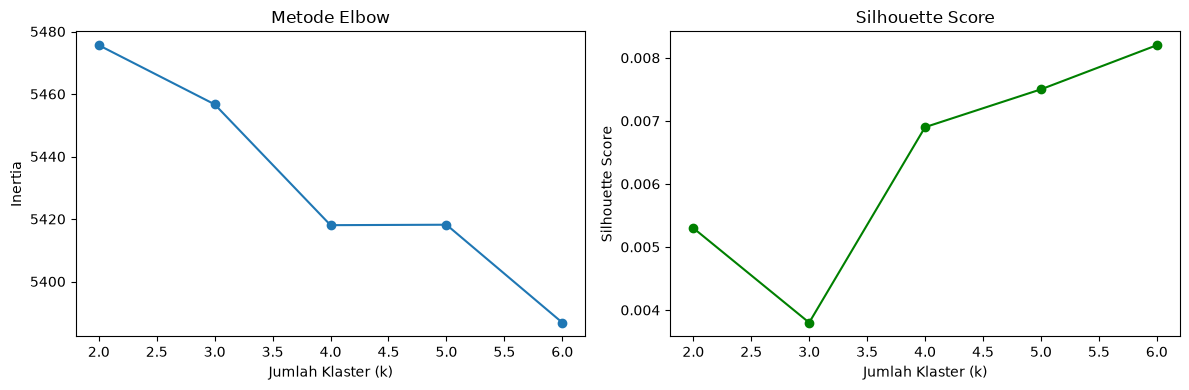

In [12]:
# Grafik perbandingan inertia dan silhouette score
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(tabel_hasil['Jumlah Klaster'], tabel_hasil['Inertia'], marker='o')
ax[0].set_xlabel("Jumlah Klaster (k)")
ax[0].set_ylabel("Inertia")
ax[0].set_title("Metode Elbow")

ax[1].plot(tabel_hasil['Jumlah Klaster'], tabel_hasil['Silhouette Score'], marker='o', color='green')
ax[1].set_xlabel("Jumlah Klaster (k)")
ax[1].set_ylabel("Silhouette Score")
ax[1].set_title("Silhouette Score")

plt.tight_layout()
plt.show()

Selanjutnya kata penciri dan bentuk sebaran klaster dilihat untuk beberapa nilai k. Kata penciri yang ditampilkan 5 kata saja per klaster supaya ringkas.

In [13]:
# Kata penciri untuk tiap jumlah klaster
for k in daftar_k:
    print(f"=== k = {k} ===")
    tampilkan_kata_penciri(model_k[k][0], jumlah_kata=5)
    print()

=== k = 2 ===
Klaster 0: im, just, ill, come, ur
Klaster 1: ok, lor, thanx, ill, come

=== k = 3 ===
Klaster 0: ok, just, come, ur, dont
Klaster 1: later, sorry, ill, meeting, help
Klaster 2: im, home, going, na, gon

=== k = 4 ===
Klaster 0: im, home, going, na, gon
Klaster 1: later, sorry, ill, meeting, help
Klaster 2: ok, lor, thanx, come, ur
Klaster 3: just, ur, come, dont, ltgt

=== k = 5 ===
Klaster 0: im, home, going, na, gon
Klaster 1: ill, come, ltgt, got, just
Klaster 2: ok, lor, thanx, come, ill
Klaster 3: know, dont, good, day, love
Klaster 4: free, new, mobile, txt, text

=== k = 6 ===
Klaster 0: later, sorry, ill, meeting, help
Klaster 1: just, ur, ltgt, dont, know
Klaster 2: im, home, going, na, gon
Klaster 3: come, tomorrow, home, want, time
Klaster 4: ok, lor, thanx, ill, prob
Klaster 5: great, princess, day, hope, good



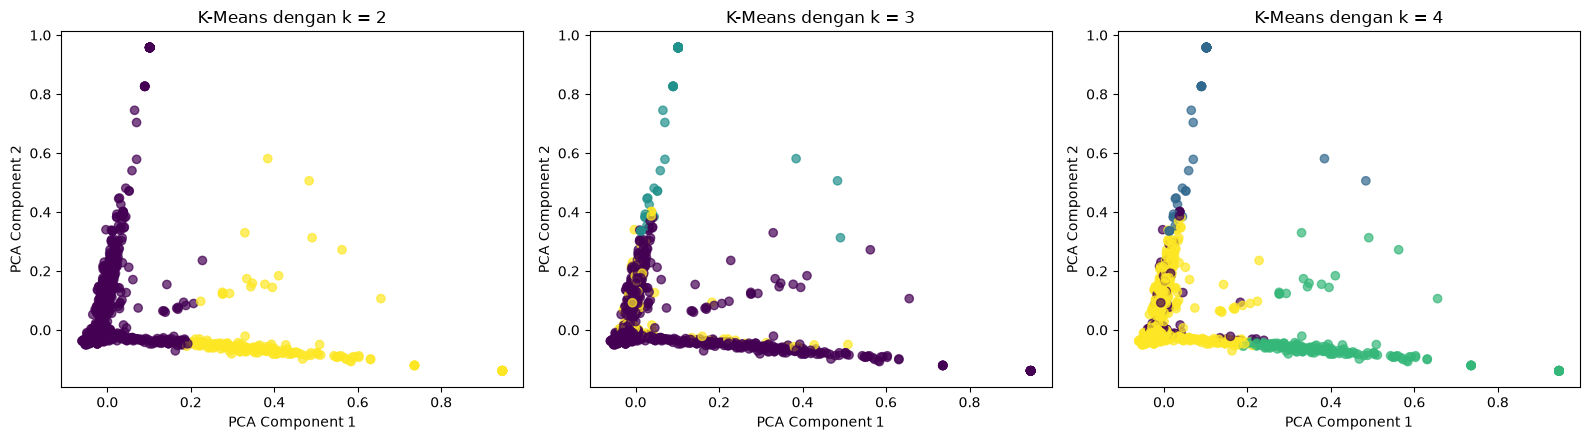

In [14]:
# Sebaran klaster di PCA untuk k = 2, 3, dan 4
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for i, k in enumerate([2, 3, 4]):
    ax[i].scatter(X_pca[:, 0], X_pca[:, 1], c=model_k[k][1], cmap='viridis', alpha=0.7)
    ax[i].set_title(f"K-Means dengan k = {k}")
    ax[i].set_xlabel("PCA Component 1")
    ax[i].set_ylabel("PCA Component 2")
plt.tight_layout()
plt.show()

In [15]:
# Ringkasan otomatis hasil perbandingan
terbaik = tabel_hasil.loc[tabel_hasil['Silhouette Score'].idxmax()]
print("Silhouette score tertinggi ada pada k =", int(terbaik['Jumlah Klaster']),
      "dengan nilai", terbaik['Silhouette Score'])
print("Silhouette score untuk k = 2 (sesuai modul):",
      tabel_hasil.loc[tabel_hasil['Jumlah Klaster'] == 2, 'Silhouette Score'].values[0])

Silhouette score tertinggi ada pada k = 6 dengan nilai 0.0082
Silhouette score untuk k = 2 (sesuai modul): 0.0053


**Cara membaca hasil perbandingan:**

- Pada grafik elbow, perhatikan di k berapa penurunan inertia mulai melandai.
- Pada grafik silhouette, nilai yang lebih tinggi berarti klaster lebih rapi.
- Nilai silhouette pada data teks biasanya kecil (mendekati 0). Itu wajar, karena teks ditulis dengan kata yang sangat beragam sehingga batas antar klaster tidak tegas.
- Kata penciri pada tiap k membantu menilai apakah penambahan klaster menghasilkan kelompok yang benar-benar punya tema berbeda, atau hanya memecah kelompok yang sama.

## Tahap 10. Kesimpulan

1. Seluruh tahap klasterisasi teks sudah dikerjakan secara berurutan: membaca data, mengecek nilai kosong, preprocessing, TF-IDF, K-Means, visualisasi PCA, membaca isi klaster, dan membandingkan jumlah klaster.
2. Preprocessing (lowercase, hapus angka dan tanda baca, tokenisasi, lemmatization) membuat teks SMS yang awalnya berantakan menjadi seragam, sehingga kata yang sama tidak dihitung sebagai kata berbeda.
3. TF-IDF berhasil mengubah teks menjadi matriks angka yang bisa diproses K-Means. Matriksnya didominasi nilai 0 karena tiap pesan hanya memakai sedikit kata dari seluruh kosakata.
4. Dengan jumlah klaster 2 sesuai modul, K-Means membagi pesan berdasarkan kemiripan kata. Isi tiap klaster bisa dibaca dari kata penciri dan contoh pesannya (tahap 8).
5. Visualisasi PCA hanya mewakili sebagian informasi data, sehingga klaster tampak ada yang menumpuk. Gambar ini lebih cocok sebagai gambaran umum, bukan ukuran kualitas klaster.
6. Jumlah klaster 2 dari modul belum tentu yang paling cocok, jadi di tahap 9 dibandingkan dengan k = 3 sampai 6. Pilihan jumlah klaster yang baik sebaiknya dilihat dari grafik elbow, silhouette score (nilainya kecil, mendekati 0, seperti umumnya data teks), dan apakah kata penciri tiap klaster masuk akal.
7. K-Means mengelompokkan berdasarkan kemiripan kata, bukan berdasarkan makna atau label. Jadi hasil klaster tidak harus sama dengan kolom `Category` (ham/spam).